# Claims Cost Driver Analysis

## Overview

This notebook analyzes Medicare claims data to identify cost drivers, utilization patterns, and high-cost cohorts. It uses beneficiary summary and inpatient/outpatient claims to produce interpretable metrics and recommendations.

## Data files & how to run

Place the following CSV files in `data/raw/`:

- `DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv`
- `DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv`
- `DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv`

Run all cells in order (Cell → Run All). Dependencies: pandas, numpy, matplotlib.

## Load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# DE-SynPUF date fields (CLM_FROM_DT, CLM_ADMSN_DT, BENE_BIRTH_DT) are YYYYMMDD integers.
# Parsing without format= causes pandas to misinterpret them (e.g. as Unix -> 1970).
def parse_yyyymmdd(series):
    """Convert DE-SynPUF YYYYMMDD values to datetime. Required for correct time-series and charts."""
    s = series.astype(str).str.strip().str.replace(r'\.0$', '', regex=True)
    return pd.to_datetime(s, format="%Y%m%d", errors="coerce")

PROJECT_ROOT = "/Users/ahannair/Desktop/HealthcareCostDriverAnalysis"
DATA_DIR = os.path.join(PROJECT_ROOT, "data", "raw")

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("DATA_DIR exists?:", os.path.exists(DATA_DIR))
print("Files in DATA_DIR:", os.listdir(DATA_DIR))

df_beneficiary = pd.read_csv(
    os.path.join(DATA_DIR, "DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv")
)

df_inpatient = pd.read_csv(
    os.path.join(DATA_DIR, "DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv")
)

df_outpatient = pd.read_csv(
    os.path.join(DATA_DIR, "DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv")
)

print("Shapes:")
print("Beneficiary:", df_beneficiary.shape)
print("Inpatient:", df_inpatient.shape)
print("Outpatient:", df_outpatient.shape)

print("\n--- Beneficiary head() ---")
display(df_beneficiary.head())

print("\n--- Inpatient head() ---")
display(df_inpatient.head())

print("\n--- Outpatient head() ---")
display(df_outpatient.head())

PROJECT_ROOT: /Users/ahannair/Desktop/HealthcareCostDriverAnalysis
DATA_DIR: /Users/ahannair/Desktop/HealthcareCostDriverAnalysis/data/raw
DATA_DIR exists?: True
Files in DATA_DIR: ['DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv', 'DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv', 'DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv']


/var/folders/g_/vz_j2frx2h98vvfg2n4fmblm0000gn/T/ipykernel_48810/2544223428.py:29: DtypeWarning: Columns (21,23,24,25,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  df_outpatient = pd.read_csv(


Shapes:
Beneficiary: (116352, 32)
Inpatient: (66773, 81)
Outpatient: (790790, 76)

--- Beneficiary head() ---


,DESYNPUF_ID,BENE_BIRTH_DT,BENE_DEATH_DT,BENE_SEX_IDENT_CD,BENE_RACE_CD,BENE_ESRD_IND,SP_STATE_CODE,BENE_COUNTY_CD,BENE_HI_CVRAGE_TOT_MONS,BENE_SMI_CVRAGE_TOT_MONS,...,SP_STRKETIA,MEDREIMB_IP,BENRES_IP,PPPYMT_IP,MEDREIMB_OP,BENRES_OP,PPPYMT_OP,MEDREIMB_CAR,BENRES_CAR,PPPYMT_CAR
0,00013D2EFD8E45D1,19230501,NaN,1,1,0,26,950,12,12,...,2,0.0,0.0,0.0,50.0,10.0,0.0,0.0,0.0,0.0
1,00016F745862898F,19430101,NaN,1,1,0,39,230,12,12,...,2,0.0,0.0,0.0,0.0,0.0,0.0,700.0,240.0,0.0
2,0001FDD721E223DC,19360901,NaN,2,1,0,39,280,12,12,...,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,00021CA6FF03E670,19410601,NaN,1,5,0,6,290,0,0,...,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00024B3D2352D2D0,19360801,NaN,1,1,0,52,590,12,12,...,2,0.0,0.0,0.0,30.0,40.0,0.0,220.0,80.0,0.0



--- Inpatient head() ---


,DESYNPUF_ID,CLM_ID,SEGMENT,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,CLM_PMT_AMT,NCH_PRMRY_PYR_CLM_PD_AMT,AT_PHYSN_NPI,OP_PHYSN_NPI,...,HCPCS_CD_36,HCPCS_CD_37,HCPCS_CD_38,HCPCS_CD_39,HCPCS_CD_40,HCPCS_CD_41,HCPCS_CD_42,HCPCS_CD_43,HCPCS_CD_44,HCPCS_CD_45
0,00013D2EFD8E45D1,196661176988405,1,20100312.0,20100313.0,2600GD,4000.0,0.0,3.139084e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00016F745862898F,196201177000368,1,20090412.0,20090418.0,3900MB,26000.0,0.0,6.476809e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00016F745862898F,196661177015632,1,20090831.0,20090902.0,3900HM,5000.0,0.0,6.119985e+08,6.119985e+08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00016F745862898F,196091176981058,1,20090917.0,20090920.0,3913XU,5000.0,0.0,4.971603e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00016F745862898F,196261176983265,1,20100626.0,20100701.0,3900MB,16000.0,0.0,6.408400e+09,1.960860e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Outpatient head() ---


,DESYNPUF_ID,CLM_ID,SEGMENT,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,CLM_PMT_AMT,NCH_PRMRY_PYR_CLM_PD_AMT,AT_PHYSN_NPI,OP_PHYSN_NPI,...,HCPCS_CD_36,HCPCS_CD_37,HCPCS_CD_38,HCPCS_CD_39,HCPCS_CD_40,HCPCS_CD_41,HCPCS_CD_42,HCPCS_CD_43,HCPCS_CD_44,HCPCS_CD_45
0,00013D2EFD8E45D1,542192281063886,1,20080904.0,20080904.0,2600RA,50.0,0.0,4.824842e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00016F745862898F,542272281166593,1,20090602.0,20090602.0,3901GS,30.0,0.0,2.963420e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00016F745862898F,542282281644416,1,20090623.0,20090623.0,3939PG,30.0,0.0,5.737808e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0001FDD721E223DC,542642281250669,1,20091011.0,20091011.0,3902NU,30.0,0.0,1.233848e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00024B3D2352D2D0,542242281386963,1,20080712.0,20080712.0,5200TV,30.0,0.0,9.688809e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data dictionary

Document key columns and meanings for beneficiary, inpatient, and outpatient datasets (e.g., IDs, dates, payment/cost fields, diagnosis codes).

In [2]:
# Use short names for clarity in this section
bene_df = df_beneficiary
inpatient_df = df_inpatient
outpatient_df = df_outpatient

# --- Print column names for each table ---
print("Beneficiary columns:", list(bene_df.columns))
print("\nInpatient columns:", list(inpatient_df.columns))
print("\nOutpatient columns:", list(outpatient_df.columns))

# --- Detect member ID column (must exist in all 3 tables) ---
MEMBER_ID_CANDIDATES = ["DESYNPUF_ID", "BENE_ID", "bene_id", "member_id"]
all_dfs = [bene_df, inpatient_df, outpatient_df]
member_id_col = None
for cand in MEMBER_ID_CANDIDATES:
    if all(cand in df.columns for df in all_dfs):
        member_id_col = cand
        break
if member_id_col is None:
    raise ValueError("No common member ID column found among DESYNPUF_ID, BENE_ID, bene_id, member_id")
print(f"\nMember ID column (in all 3 tables): {member_id_col}")

# --- Detect claim date column for claims tables (prefer from/start date) ---
DATE_CANDIDATES = ["CLM_FROM_DT", "CLM_ADMSN_DT", "CLM_THRU_DT"]  # from/start first, then fallback

def _first_found(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

inpatient_date_col = _first_found(inpatient_df, DATE_CANDIDATES)
outpatient_date_col = _first_found(outpatient_df, DATE_CANDIDATES)
print(f"Inpatient claim date column: {inpatient_date_col}")
print(f"Outpatient claim date column: {outpatient_date_col}")

# --- Detect cost column for claims tables ---
COST_CANDIDATES = ["CLM_PMT_AMT", "CLM_TOT_CHRG_AMT", "NCH_CLM_PMT_AMT"]
inpatient_cost_col = _first_found(inpatient_df, COST_CANDIDATES)
outpatient_cost_col = _first_found(outpatient_df, COST_CANDIDATES)
print(f"Inpatient cost column: {inpatient_cost_col}")
print(f"Outpatient cost column: {outpatient_cost_col}")

# --- Optional: sex and age (only if present in beneficiary table) ---
sex_col = None
age_col = None
for c in ["BENE_SEX_IDENT_CD", "SEX", "sex", "gender"]:
    if c in bene_df.columns:
        sex_col = c
        break
for c in ["BENE_AGE_AT_END_REF_YR", "AGE", "age", "BENE_AGE"]:
    if c in bene_df.columns:
        age_col = c
        break

# --- Build data_dictionary: only columns we use ---
rows = [
    ("beneficiary", member_id_col, "Member/beneficiary unique identifier (join key across tables)."),
    ("inpatient", member_id_col, "Member/beneficiary unique identifier (join key)."),
    ("outpatient", member_id_col, "Member/beneficiary unique identifier (join key)."),
]
if inpatient_date_col:
    rows.append(("inpatient", inpatient_date_col, "Claim from/admission or through date (claim service date)."))
if outpatient_date_col:
    rows.append(("outpatient", outpatient_date_col, "Claim from/admission or through date (claim service date)."))
if inpatient_cost_col:
    rows.append(("inpatient", inpatient_cost_col, "Claim payment or total charge amount (cost)."))
if outpatient_cost_col:
    rows.append(("outpatient", outpatient_cost_col, "Claim payment or total charge amount (cost)."))
if sex_col:
    rows.append(("beneficiary", sex_col, "Beneficiary sex/gender code."))
if age_col:
    rows.append(("beneficiary", age_col, "Beneficiary age (e.g., at end of reference year)."))

data_dictionary = pd.DataFrame(rows, columns=["table", "column", "description"])
display(data_dictionary)

Beneficiary columns: ['DESYNPUF_ID', 'BENE_BIRTH_DT', 'BENE_DEATH_DT', 'BENE_SEX_IDENT_CD', 'BENE_RACE_CD', 'BENE_ESRD_IND', 'SP_STATE_CODE', 'BENE_COUNTY_CD', 'BENE_HI_CVRAGE_TOT_MONS', 'BENE_SMI_CVRAGE_TOT_MONS', 'BENE_HMO_CVRAGE_TOT_MONS', 'PLAN_CVRG_MOS_NUM', 'SP_ALZHDMTA', 'SP_CHF', 'SP_CHRNKIDN', 'SP_CNCR', 'SP_COPD', 'SP_DEPRESSN', 'SP_DIABETES', 'SP_ISCHMCHT', 'SP_OSTEOPRS', 'SP_RA_OA', 'SP_STRKETIA', 'MEDREIMB_IP', 'BENRES_IP', 'PPPYMT_IP', 'MEDREIMB_OP', 'BENRES_OP', 'PPPYMT_OP', 'MEDREIMB_CAR', 'BENRES_CAR', 'PPPYMT_CAR']

Inpatient columns: ['DESYNPUF_ID', 'CLM_ID', 'SEGMENT', 'CLM_FROM_DT', 'CLM_THRU_DT', 'PRVDR_NUM', 'CLM_PMT_AMT', 'NCH_PRMRY_PYR_CLM_PD_AMT', 'AT_PHYSN_NPI', 'OP_PHYSN_NPI', 'OT_PHYSN_NPI', 'CLM_ADMSN_DT', 'ADMTNG_ICD9_DGNS_CD', 'CLM_PASS_THRU_PER_DIEM_AMT', 'NCH_BENE_IP_DDCTBL_AMT', 'NCH_BENE_PTA_COINSRNC_LBLTY_AM', 'NCH_BENE_BLOOD_DDCTBL_LBLTY_AM', 'CLM_UTLZTN_DAY_CNT', 'NCH_BENE_DSCHRG_DT', 'CLM_DRG_CD', 'ICD9_DGNS_CD_1', 'ICD9_DGNS_CD_2', 'ICD9_DGNS_CD

,table,column,description
0,beneficiary,DESYNPUF_ID,Member/beneficiary unique identifier (join key...
1,inpatient,DESYNPUF_ID,Member/beneficiary unique identifier (join key).
2,outpatient,DESYNPUF_ID,Member/beneficiary unique identifier (join key).
3,inpatient,CLM_FROM_DT,Claim from/admission or through date (claim se...
4,outpatient,CLM_FROM_DT,Claim from/admission or through date (claim se...
5,inpatient,CLM_PMT_AMT,Claim payment or total charge amount (cost).
6,outpatient,CLM_PMT_AMT,Claim payment or total charge amount (cost).
7,beneficiary,BENE_SEX_IDENT_CD,Beneficiary sex/gender code.


## Cleaning & validation

Handle missing values, duplicates, invalid dates, and out-of-range cost/payment fields. Report row counts before/after and any exclusions.

In [3]:
# --- Parse claim dates with YYYYMMDD format (DE-SynPUF); avoid default parsing which gives 1970 ---
inpatient_date_col_use = "CLM_ADMSN_DT" if "CLM_ADMSN_DT" in df_inpatient.columns else (inpatient_date_col or "CLM_FROM_DT")
outpatient_date_col_use = outpatient_date_col or "CLM_FROM_DT"
ip_parsed = parse_yyyymmdd(df_inpatient[inpatient_date_col_use])
op_parsed = parse_yyyymmdd(df_outpatient[outpatient_date_col_use])

# --- Missingness summary for key fields ---
def _missing_summary(df, name, id_col, date_col, cost_col):
    out = []
    for col, label in [(id_col, "member_id"), (date_col, "date"), (cost_col, "cost")]:
        if col is None or col not in df.columns:
            continue
        missing = df[col].isna().sum()
        pct = 100 * missing / len(df) if len(df) > 0 else 0
        out.append(f"  {label} ({col}): {missing} missing ({pct:.2f}%)")
    if out:
        print(f"{name}:")
        print("\n".join(out))
        print()

_missing_summary(df_inpatient, "Inpatient", member_id_col, inpatient_date_col_use, inpatient_cost_col)
_missing_summary(df_outpatient, "Outpatient", member_id_col, outpatient_date_col_use, outpatient_cost_col)

# --- Validate cost: counts and cleaned copy (negatives -> NaN, do not drop) ---
def _cost_report(df, name, cost_col):
    if cost_col is None or cost_col not in df.columns:
        return df.copy()
    s = df[cost_col]
    neg = (s < 0).sum()
    zero = (s == 0).sum()
    missing = s.isna().sum()
    print(f"{name} cost ({cost_col}): negative={neg}, zero={zero}, missing={missing}")
    cleaned = df.copy()
    cleaned.loc[cleaned[cost_col] < 0, cost_col] = np.nan
    return cleaned

df_inpatient_cost_checked = _cost_report(df_inpatient, "Inpatient", inpatient_cost_col)
df_outpatient_cost_checked = _cost_report(df_outpatient, "Outpatient", outpatient_cost_col)

# --- Standardized clean tables: member_id, claim_date (parsed YYYYMMDD), cost, source ---
def _standardize(df, id_col, date_series, cost_col, source_label):
    out = pd.DataFrame()
    out["member_id"] = df[id_col].values if id_col in df.columns else np.nan
    out["claim_date"] = date_series.values if date_series is not None else pd.NaT
    out["cost"] = df[cost_col].values if cost_col and cost_col in df.columns else np.nan
    out["source"] = source_label
    return out

inpatient_clean = _standardize(df_inpatient_cost_checked, member_id_col, ip_parsed, inpatient_cost_col, "inpatient")
outpatient_clean = _standardize(df_outpatient_cost_checked, member_id_col, op_parsed, outpatient_cost_col, "outpatient")

n_in_raw = len(df_inpatient)
n_out_raw = len(df_outpatient)
claims_all = pd.concat([inpatient_clean, outpatient_clean], ignore_index=True)
# Drop rows missing member_id or claim_date before building monthly metrics
claims_all = claims_all.dropna(subset=["member_id", "claim_date"]).copy()
claims_all["year_month"] = claims_all["claim_date"].dt.to_period("M").astype(str)
n_after = len(claims_all)

print("\nRow counts:")
print(f"  Before standardization: inpatient={n_in_raw}, outpatient={n_out_raw}, total={n_in_raw + n_out_raw}")
print(f"  After drop missing member_id/claim_date: total={n_after}")

valid_dates = claims_all["claim_date"].dropna()
if len(valid_dates) > 0:
    print(f"  Claim date range: {valid_dates.min()} to {valid_dates.max()}")
else:
    print("  Claim date range: (no valid dates)")

# --- Date sanity check ---
pct_nat_ip = 100 * ip_parsed.isna().sum() / len(ip_parsed) if len(ip_parsed) > 0 else 0
pct_nat_op = 100 * op_parsed.isna().sum() / len(op_parsed) if len(op_parsed) > 0 else 0
print("\nDate sanity check:")
print(f"  Inpatient: min={ip_parsed.min()}, max={ip_parsed.max()}, % NaT={pct_nat_ip:.2f}")
print(f"  Outpatient: min={op_parsed.min()}, max={op_parsed.max()}, % NaT={pct_nat_op:.2f}")
print(f"  Distinct year_month in claims_all: {claims_all["year_month"].nunique()} (expect many, e.g. 2008–2010)")

# --- Assertion-style checks ---
assert len(claims_all) > 0, "claims_all is empty after standardization; check input data and column detection."
null_member = claims_all["member_id"].isna().sum()
pct_null = 100 * null_member / len(claims_all)
assert pct_null <= 1.0, (
    f"member_id has too many nulls: {null_member} ({pct_null:.2f}%). Maximum allowed is 1%."
)
print("\nValidation passed: claims_all is non-empty and member_id nulls within 1%.")

Inpatient:
  member_id (DESYNPUF_ID): 0 missing (0.00%)
  date (CLM_ADMSN_DT): 0 missing (0.00%)
  cost (CLM_PMT_AMT): 0 missing (0.00%)

Outpatient:
  member_id (DESYNPUF_ID): 0 missing (0.00%)
  date (CLM_FROM_DT): 11253 missing (1.42%)
  cost (CLM_PMT_AMT): 0 missing (0.00%)

Inpatient cost (CLM_PMT_AMT): negative=55, zero=2160, missing=0
Outpatient cost (CLM_PMT_AMT): negative=2566, zero=30105, missing=0

Row counts:
  Before standardization: inpatient=66773, outpatient=790790, total=857563
  After drop missing member_id/claim_date: total=846310
  Claim date range: 2007-11-27 00:00:00 to 2010-12-31 00:00:00

Date sanity check:
  Inpatient: min=2007-11-27 00:00:00, max=2010-12-30 00:00:00, % NaT=0.00
  Outpatient: min=2007-12-12 00:00:00, max=2010-12-31 00:00:00, % NaT=1.42
  Distinct year_month in claims_all: 38 (expect many, e.g. 2008–2010)

Validation passed: claims_all is non-empty and member_id nulls within 1%.


## Feature engineering

Derive age groups, cost per encounter, utilization flags, and other features needed for cost driver and cohort analysis.

In [4]:
# --- Add time and source flags to claims_all ---
claims_all["year"] = claims_all["claim_date"].dt.year.astype("Int64")
claims_all["month"] = claims_all["claim_date"].dt.to_period("M")
claims_all["year_month"] = claims_all["claim_date"].dt.to_period("M").astype(str)
claims_all["is_inpatient"] = claims_all["source"] == "inpatient"
claims_all["is_outpatient"] = claims_all["source"] == "outpatient"

# --- Member–month rollups (group by member_id + year_month) ---
member_month = claims_all.groupby(["member_id", "year_month"], dropna=False).agg(
    total_cost=("cost", "sum"),
    claims_count=("cost", "size"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
).reset_index()
# Ensure integer counts
member_month["inpatient_claims"] = member_month["inpatient_claims"].astype(int)
member_month["outpatient_claims"] = member_month["outpatient_claims"].astype(int)

# --- Member-level rollups (group by member_id) ---
member_summary = claims_all.groupby("member_id", dropna=False).agg(
    total_cost=("cost", "sum"),
    total_claims=("cost", "size"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
    active_months=("year_month", "nunique"),
).reset_index()
member_summary["inpatient_claims"] = member_summary["inpatient_claims"].astype(int)
member_summary["outpatient_claims"] = member_summary["outpatient_claims"].astype(int)
member_summary["avg_monthly_cost"] = np.where(
    member_summary["active_months"] > 0,
    member_summary["total_cost"] / member_summary["active_months"],
    np.nan,
)

# --- Preview and basic stats ---
print("member_month head():")
display(member_month.head())

print("member_summary head():")
display(member_summary.head())

print("member_month basic stats:")
display(member_month.describe())

print("member_summary basic stats:")
display(member_summary.describe())

member_month head():


,member_id,year_month,total_cost,claims_count,inpatient_claims,outpatient_claims
0,00013D2EFD8E45D1,2008-09,50.0,1,0,1
1,00013D2EFD8E45D1,2010-03,4000.0,1,1,0
2,00016F745862898F,2009-04,26000.0,1,1,0
3,00016F745862898F,2009-06,60.0,2,0,2
4,00016F745862898F,2009-08,5000.0,1,1,0


member_summary head():


,member_id,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months,avg_monthly_cost
0,00013D2EFD8E45D1,4050.0,2,1,1,2,2025.000000
1,00016F745862898F,52060.0,6,4,2,5,10412.000000
2,0001FDD721E223DC,30.0,1,0,1,1,30.000000
3,00024B3D2352D2D0,160.0,4,0,4,4,40.000000
4,0002F28CE057345B,2870.0,18,0,18,13,220.769231


member_month basic stats:


,total_cost,claims_count,inpatient_claims,outpatient_claims
count,652039.000000,652039.000000,652039.000000,652039.000000
mean,1301.557683,1.297944,0.102406,1.195537
std,4352.925756,0.604164,0.324971,0.645249
min,0.000000,1.000000,0.000000,0.000000
25%,50.000000,1.000000,0.000000,1.000000
50%,100.000000,1.000000,0.000000,1.000000
75%,500.000000,1.000000,0.000000,1.000000
max,128150.000000,8.000000,4.000000,8.000000


member_summary basic stats:


,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months,avg_monthly_cost
count,86705.000000,86705.000000,86705.000000,86705.000000,86705.000000,86705.000000
mean,9787.974973,9.760798,0.770117,8.990681,7.520201,1389.004681
std,16369.877013,8.386204,1.210927,7.922480,5.499416,2758.309088
min,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,670.000000,3.000000,0.000000,3.000000,3.000000,152.000000
50%,3450.000000,7.000000,0.000000,7.000000,6.000000,462.857143
75%,11730.000000,14.000000,1.000000,13.000000,11.000000,1520.000000
max,234190.000000,60.000000,14.000000,59.000000,29.000000,69000.000000


## Core cost & utilization metrics

Summarize total/mean cost, encounter counts, and utilization rates (e.g., inpatient vs outpatient) at beneficiary or claim level.

Overall totals:
  Total spend:     848,666,370.00
  Unique members: 86,705
  Total claims:   846,310
  Date range:     2007-11-27 00:00:00 to 2010-12-31 00:00:00

Top 12 months by total_cost:


,year_month,total_cost,total_claims,active_members,pmpm_proxy
9,2008-08,30819330.0,29790,22104,1394.287459
11,2008-10,30777000.0,29990,22355,1376.738985
6,2008-05,30725410.0,27506,20216,1519.856055
13,2008-12,30003300.0,30771,23105,1298.563082
16,2009-03,29768820.0,30729,23403,1272.008717
14,2009-01,29726410.0,30969,23243,1278.940326
8,2008-07,29722270.0,28886,21365,1391.166394
7,2008-06,29532950.0,27520,20478,1442.179412
18,2009-05,29165220.0,30624,23443,1244.090773
10,2008-09,29082470.0,28873,21733,1338.170984


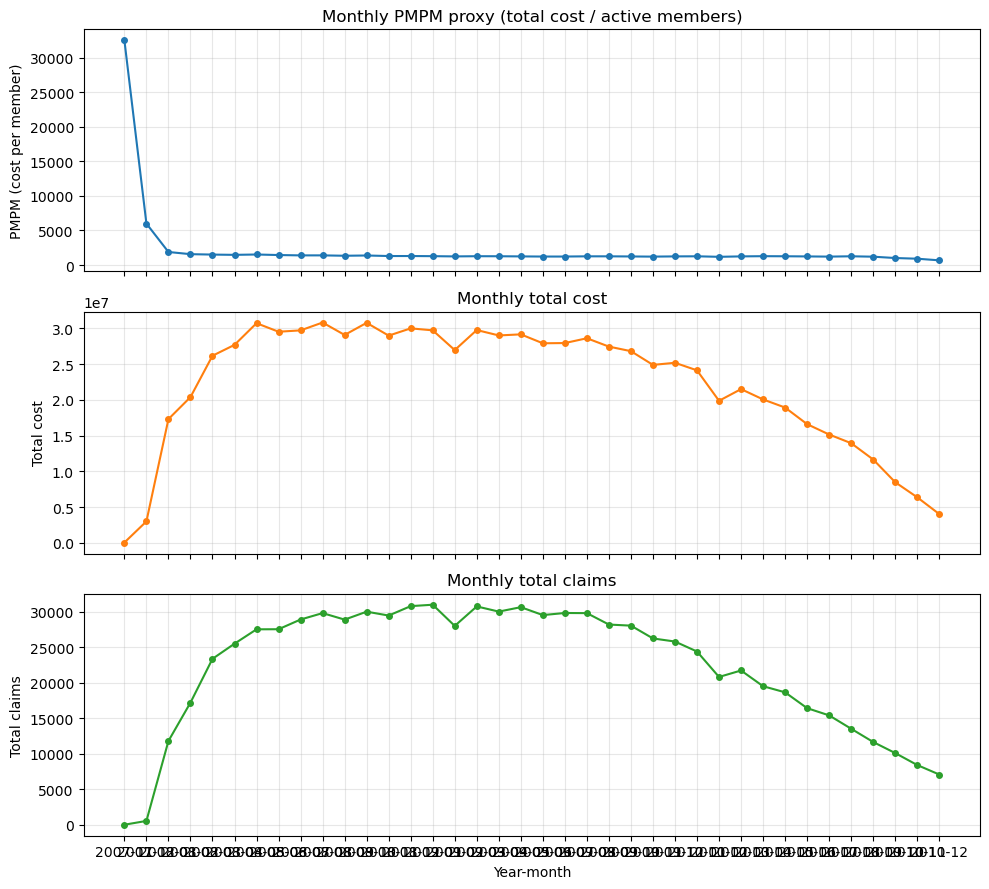

In [5]:
# --- Overall totals ---
total_spend = claims_all["cost"].sum()
unique_members = claims_all["member_id"].nunique()
total_claims = len(claims_all)
valid_dates = claims_all["claim_date"].dropna()
date_min = valid_dates.min() if len(valid_dates) > 0 else None
date_max = valid_dates.max() if len(valid_dates) > 0 else None

print("Overall totals:")
print(f"  Total spend:     {total_spend:,.2f}")
print(f"  Unique members: {unique_members:,}")
print(f"  Total claims:   {total_claims:,}")
print(f"  Date range:     {date_min} to {date_max}")

# --- Monthly summary (group by year_month) ---
monthly_summary = claims_all.groupby("year_month", dropna=False).agg(
    total_cost=("cost", "sum"),
    total_claims=("cost", "size"),
    active_members=("member_id", "nunique"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
).reset_index()
monthly_summary["inpatient_claims"] = monthly_summary["inpatient_claims"].astype(int)
monthly_summary["outpatient_claims"] = monthly_summary["outpatient_claims"].astype(int)
monthly_summary["pmpm_proxy"] = np.where(
    monthly_summary["active_members"] > 0,
    monthly_summary["total_cost"] / monthly_summary["active_members"],
    np.nan,
)

# --- Top 12 months by total_cost ---
top12 = monthly_summary.nlargest(12, "total_cost")[["year_month", "total_cost", "total_claims", "active_members", "pmpm_proxy"]]
print("\nTop 12 months by total_cost:")
display(top12)

# --- Charts: pmpm_proxy, total_cost, total_claims ---
# Sort by year_month for clean time order
ms = monthly_summary.dropna(subset=["year_month"]).sort_values("year_month")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(ms["year_month"], ms["pmpm_proxy"], marker="o", markersize=4)
axes[0].set_ylabel("PMPM (cost per member)")
axes[0].set_title("Monthly PMPM proxy (total cost / active members)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(ms["year_month"], ms["total_cost"], marker="o", markersize=4, color="C1")
axes[1].set_ylabel("Total cost")
axes[1].set_title("Monthly total cost")
axes[1].grid(True, alpha=0.3)

axes[2].plot(ms["year_month"], ms["total_claims"], marker="o", markersize=4, color="C2")
axes[2].set_ylabel("Total claims")
axes[2].set_xlabel("Year-month")
axes[2].set_title("Monthly total claims")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Descriptive cost drivers (charts)

Visualize cost and utilization by key dimensions (e.g., age, gender, chronic conditions, year) using matplotlib.

Top 15 members by total_cost:


,member_id,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months
0,CD57573A5B77AAFE,234190.0,55,14,41,21
1,E2D39E24FCF427D5,231280.0,46,9,37,18
2,3A9D94388C426924,213970.0,33,12,21,21
3,11B3642EFC2521EB,207120.0,40,8,32,29
4,AEF310232161AC91,205420.0,42,9,33,26
5,7E00D9D78DAA008D,199280.0,30,9,21,20
6,FC02104A9F15D57C,194930.0,37,13,24,22
7,F8F72B475A3381DC,193790.0,44,8,36,20
8,AEE2353E80207F0C,190250.0,13,9,4,9
9,8FBF91DCA969CB07,189380.0,42,5,37,18


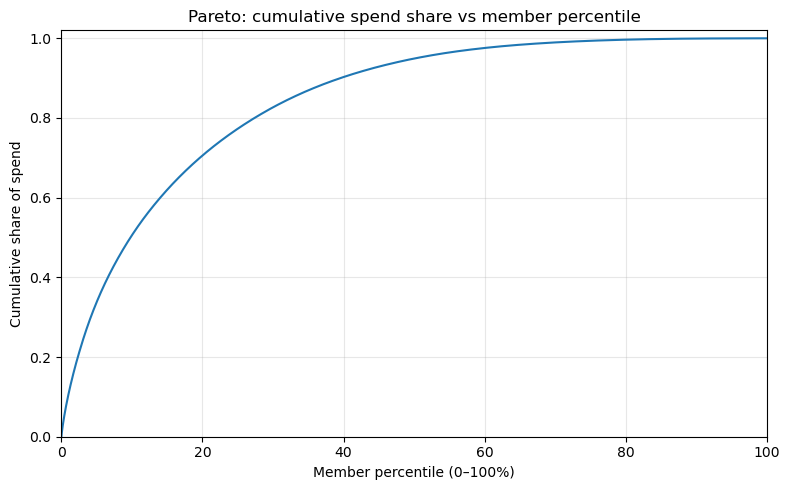

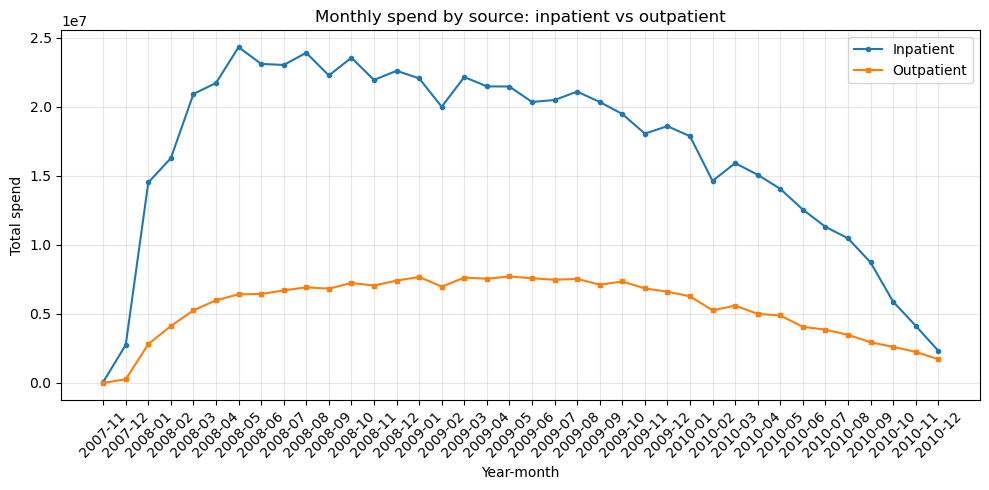

In [6]:
# --- Table: top 15 members by total_cost ---
top15_members = (
    member_summary.nlargest(15, "total_cost")[
        ["member_id", "total_cost", "total_claims", "inpatient_claims", "outpatient_claims", "active_months"]
    ]
    .reset_index(drop=True)
)
print("Top 15 members by total_cost:")
display(top15_members)

# --- Pareto: cumulative spend share vs member percentile ---
ms_sorted = member_summary.sort_values("total_cost", ascending=False).reset_index(drop=True)
total_spend_all = ms_sorted["total_cost"].sum()
n_members = len(ms_sorted)
if total_spend_all > 0 and n_members > 0:
    ms_sorted["cum_cost"] = ms_sorted["total_cost"].cumsum()
    ms_sorted["cum_share_spend"] = ms_sorted["cum_cost"] / total_spend_all
    ms_sorted["member_pct"] = 100 * (np.arange(1, n_members + 1, dtype=float) / n_members)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ms_sorted["member_pct"], ms_sorted["cum_share_spend"], linewidth=1.5)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Member percentile (0–100%)")
    ax.set_ylabel("Cumulative share of spend")
    ax.set_title("Pareto: cumulative spend share vs member percentile")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Spend mix over time: inpatient vs outpatient monthly spend (two-line plot) ---
monthly_by_source = (
    claims_all.groupby(["year_month", "source"])["cost"]
    .sum()
    .unstack(fill_value=0)
)
monthly_by_source = monthly_by_source.reindex(columns=["inpatient", "outpatient"], fill_value=0)
monthly_by_source = monthly_by_source.sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
if "inpatient" in monthly_by_source.columns:
    ax.plot(monthly_by_source.index, monthly_by_source["inpatient"], label="Inpatient", marker="o", markersize=3)
if "outpatient" in monthly_by_source.columns:
    ax.plot(monthly_by_source.index, monthly_by_source["outpatient"], label="Outpatient", marker="s", markersize=3)
ax.set_xlabel("Year-month")
ax.set_ylabel("Total spend")
ax.set_title("Monthly spend by source: inpatient vs outpatient")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## High-cost cohort analysis (top 1% / 5%)

Identify beneficiaries in the top 1% and top 5% by cost; summarize their characteristics and compare to the rest of the population.

Comparison table (Top 1%, Top 5%, Bottom 95%):


,size,share_of_spend,mean_cost,median_cost,mean_claims,inpatient_rate
Top 1%,868,0.106528,104155.172811,96680.0,27.535714,1.000000
Top 5%,4336,0.337891,66133.927583,58890.0,21.184041,0.987315
Bottom 95%,82369,0.662109,6821.858466,3000.0,9.159465,0.406694


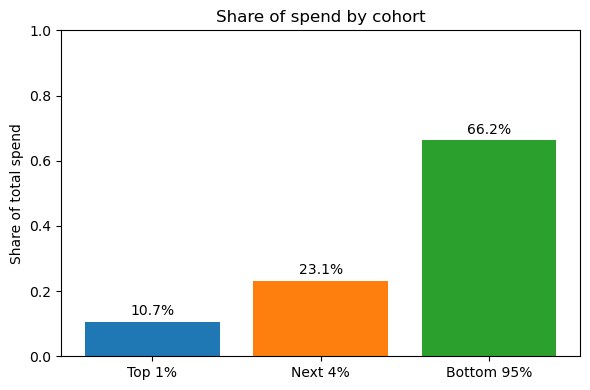

In [7]:
# Define cohorts by total_cost (sorted descending)
ms = member_summary.sort_values("total_cost", ascending=False).reset_index(drop=True)
n = len(ms)
total_spend = ms["total_cost"].sum()
n_1pct = max(1, int(np.ceil(0.01 * n)))
n_5pct = max(1, int(np.ceil(0.05 * n)))

top_1pct = ms.iloc[:n_1pct]
next_4pct = ms.iloc[n_1pct:n_5pct]   # top 5% excluding top 1%
top_5pct = ms.iloc[:n_5pct]
bottom_95pct = ms.iloc[n_5pct:]

def cohort_metrics(df, label):
    if len(df) == 0:
        return {"cohort": label, "size": 0, "share_of_spend": 0, "mean_cost": np.nan, "median_cost": np.nan, "mean_claims": np.nan, "inpatient_rate": np.nan}
    spend = df["total_cost"].sum()
    share = spend / total_spend if total_spend > 0 else 0
    return {
        "cohort": label,
        "size": len(df),
        "share_of_spend": share,
        "mean_cost": df["total_cost"].mean(),
        "median_cost": df["total_cost"].median(),
        "mean_claims": df["total_claims"].mean(),
        "inpatient_rate": (df["inpatient_claims"] >= 1).mean(),
    }

rows = [
    cohort_metrics(top_1pct, "Top 1%"),
    cohort_metrics(top_5pct, "Top 5%"),
    cohort_metrics(bottom_95pct, "Bottom 95%"),
]
comparison_table = pd.DataFrame(rows).set_index("cohort")
comparison_table.index.name = None
print("Comparison table (Top 1%, Top 5%, Bottom 95%):")
display(comparison_table)

# Bar chart: share of spend by cohort (Top 1%, Next 4%, Bottom 95%)
share_1 = top_1pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
share_next4 = next_4pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
share_bottom95 = bottom_95pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
labels = ["Top 1%", "Next 4%", "Bottom 95%"]
shares = [share_1, share_next4, share_bottom95]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, shares, color=["C0", "C1", "C2"])
ax.set_ylabel("Share of total spend")
ax.set_title("Share of spend by cohort")
ax.set_ylim(0, 1)
for b, s in zip(bars, shares):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{100 * s:.1f}%", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

Correlation with total_cost (sorted):


,correlation_with_total_cost
inpatient_claims,0.800117
avg_monthly_cost,0.577817
total_claims,0.491735
active_months,0.451446
outpatient_claims,0.398222
share_inpatient,0.352685
age,0.039425


Mean total_cost by sex:


,mean_total_cost,member_count
sex,,
Female,9824.64,48934
Male,9740.48,37771


Mean total_cost by age bin:


,mean_total_cost,member_count
age_bin,,
<65,10181.02,13856
65-74,8444.03,33709
75-84,10306.00,25961
85+,11791.79,13179


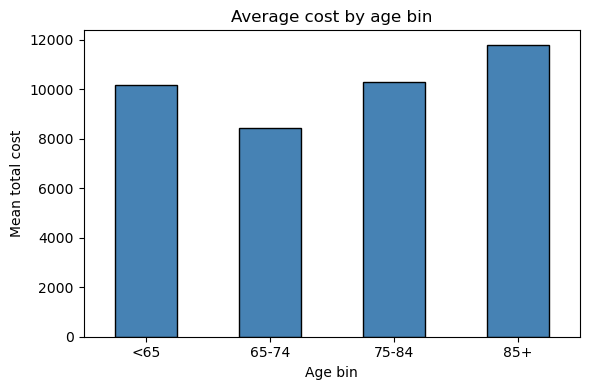


--- Interpretation ---
• Correlation table: which member-level features move with total cost (positive = higher feature, higher cost).
• Mean cost by sex: average spend differs by gender; compare mean_total_cost and member_count.
• Mean cost by age bin: older age bands (e.g. 75-84, 85+) often show higher average cost; the bar chart summarizes this.


In [8]:
# --- Build features_df at member level ---
features_df = member_summary[
    ["member_id", "total_cost", "total_claims", "inpatient_claims", "outpatient_claims", "active_months", "avg_monthly_cost"]
].copy()
features_df["share_inpatient"] = np.where(
    features_df["total_claims"] > 0,
    features_df["inpatient_claims"] / features_df["total_claims"],
    np.nan,
)

# Merge beneficiary demographics if available (use member_id_col from Data dictionary)
bene = df_beneficiary.copy()
bene = bene.rename(columns={member_id_col: "member_id"})
merge_cols = ["member_id"] + [c for c in ["BENE_SEX_IDENT_CD", "BENE_BIRTH_DT", age_col] if c and c in bene.columns]
features_df = features_df.merge(bene[merge_cols], on="member_id", how="left")

# Sex: use BENE_SEX_IDENT_CD if present
if "BENE_SEX_IDENT_CD" in features_df.columns:
    features_df["sex"] = features_df["BENE_SEX_IDENT_CD"].astype(str).replace({"1": "Male", "2": "Female", "1.0": "Male", "2.0": "Female"})
else:
    features_df["sex"] = np.nan

# Age: derive from BENE_BIRTH_DT (YYYYMMDD) if present; use age at 2008-12-31 for bins
ref_date = pd.Timestamp("2008-12-31")
if "BENE_BIRTH_DT" in features_df.columns:
    birth_dt = parse_yyyymmdd(features_df["BENE_BIRTH_DT"])
    features_df["age"] = (ref_date - birth_dt).dt.days / 365.25
    features_df["age"] = features_df["age"].round().clip(lower=0).where(features_df["age"].notna())
elif age_col and age_col in features_df.columns:
    features_df["age"] = pd.to_numeric(features_df[age_col], errors="coerce")
else:
    features_df["age"] = np.nan

# Drop temporary merge columns if present
for c in ["BENE_SEX_IDENT_CD", "BENE_BIRTH_DT"] + ([age_col] if age_col else []):
    if c in features_df.columns:
        features_df = features_df.drop(columns=[c], errors="ignore")

# --- Correlation of numeric features vs total_cost (sorted) ---
num_cols = ["total_claims", "inpatient_claims", "outpatient_claims", "active_months", "avg_monthly_cost", "share_inpatient"]
if pd.notna(features_df["age"]).any():
    num_cols.append("age")
num_cols = [c for c in num_cols if c in features_df.columns]
corr_with_cost = features_df[num_cols].corrwith(features_df["total_cost"]).sort_values(ascending=False)
corr_table = pd.DataFrame({"correlation_with_total_cost": corr_with_cost})
print("Correlation with total_cost (sorted):")
display(corr_table)

# --- Grouped mean total_cost by sex (if available) ---
if "sex" in features_df.columns and features_df["sex"].notna().any():
    mean_by_sex = features_df.groupby("sex", dropna=False)["total_cost"].agg(["mean", "count"]).round(2)
    mean_by_sex.columns = ["mean_total_cost", "member_count"]
    print("Mean total_cost by sex:")
    display(mean_by_sex)
else:
    mean_by_sex = None
    print("Sex not available; skipping mean cost by sex.")

# --- Age bins and grouped mean total_cost ---
age_bins = [0, 65, 75, 85, 150]
age_labels = ["<65", "65-74", "75-84", "85+"]
features_df["age_bin"] = pd.cut(features_df["age"], bins=age_bins, labels=age_labels, right=False)

if features_df["age"].notna().any():
    mean_by_age = features_df.groupby("age_bin", observed=True)["total_cost"].agg(["mean", "count"]).round(2)
    mean_by_age.columns = ["mean_total_cost", "member_count"]
    print("Mean total_cost by age bin:")
    display(mean_by_age)

    # Single plot: avg cost by age bin
    fig, ax = plt.subplots(figsize=(6, 4))
    mean_by_age["mean_total_cost"].plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_xlabel("Age bin")
    ax.set_ylabel("Mean total cost")
    ax.set_title("Average cost by age bin")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()
else:
    mean_by_age = None
    print("Birth date or age could not be computed; skipping age bins and plot.")

# --- Plain-English interpretation ---
print("\n--- Interpretation ---")
print("• Correlation table: which member-level features move with total cost (positive = higher feature, higher cost).")
if mean_by_sex is not None:
    print("• Mean cost by sex: average spend differs by gender; compare mean_total_cost and member_count.")
if mean_by_age is not None:
    print("• Mean cost by age bin: older age bands (e.g. 75-84, 85+) often show higher average cost; the bar chart summarizes this.")

## Driver analysis (interpretable)

Quantify which factors (demographics, conditions, utilization type) are most associated with cost—e.g., simple group comparisons or correlation-style summaries.

## Executive summary & recommendations

### Key findings

- **Spend concentration**: The Pareto analysis shows a small share of members drives a large share of total spend (e.g., top 1% and top 5% account for a disproportionate share of cost). This pattern is consistent with typical healthcare cost concentration and highlights the importance of focusing interventions on high-cost cohorts.
- **Inpatient vs. outpatient mix**: The spend-mix-over-time charts and monthly summaries show how inpatient and outpatient utilization contribute to total cost. Where inpatient share is high or growing, there may be opportunities to shift or prevent avoidable inpatient use.
- **High-cost cohort profile**: The comparison table (Top 1%, Top 5%, Bottom 95%) shows that the top cohorts have higher mean and median cost per member, higher mean claims per member, and a higher inpatient rate (fraction with ≥1 inpatient claim). These members are both heavier utilizers and more inpatient-driven.
- **Driver analysis**: Correlations and grouped means (by sex and age bin) show which member-level features move with total cost—e.g., higher inpatient share, more claims, and older age bands (e.g., 75–84, 85+) are associated with higher average cost. The bar chart of average cost by age bin quantifies the age–cost relationship.
- **Monthly trends**: Core metrics (PMPM proxy, total cost, total claims) and monthly summaries describe utilization and cost over time, including seasonal or period effects and the level of active membership by month.

### Recommendations

- **Care management targeting high-cost cohorts**: Use the top-1% and top-5% definitions and their characteristics (e.g., high inpatient rate, many claims) to target case management, care coordination, and preventive outreach to reduce avoidable admissions and improve outcomes.
- **Reducing avoidable inpatient use**: Where the inpatient share of spend is high, implement or strengthen prior authorization, discharge planning, and alternatives to admission (e.g., observation, hospital-at-home, or improved outpatient management) to lower avoidable inpatient utilization.
- **Improving outpatient management**: For members with high outpatient volume but manageable acuity, focus on care coordination, primary care attachment, and chronic disease management to improve efficiency and reduce fragmented or duplicative care.
- **Segmenting by age and risk**: Use age-bin and other driver results to tailor programs (e.g., focused support for older age bands) and to align network and benefit design with observed cost and utilization patterns.

### Limitations

- **Synthetic data**: The analysis uses synthetic/sample Medicare data; patterns may not generalize to real populations or other payers, and relationships may be simplified or biased by the data-generation process.
- **Missing clinical coding granularity**: Without detailed diagnosis and procedure coding (e.g., condition flags, HCCs, or procedure categories), driver analysis is limited to utilization and demographics; clinical drivers and avoidability cannot be assessed in depth.
- **PMPM proxy based on active members**: The PMPM proxy is computed as total cost divided by *active members* (members with at least one claim in the month), not enrollment or member-months. It therefore reflects cost per *utilizing* member and overstates true per-member-per-enrollment-month cost when many members have no claims in a given month.

## Limitations

Sample size, time period, missing data, and caveats for generalizing results.